In [1]:
import networkx as nx
import pickle
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
with open('data/data_derivatives/obs_func.gpickle', 'rb') as f:
    obs_func = pickle.load(f)

In [69]:
# Check if all nodes have timeseries attribute
all_nodes = list(obs_func.nodes)
nodes_without_timeseries = []

for node in all_nodes:
    if 'timeseries' not in obs_func.nodes[node]:
        nodes_without_timeseries.append(node)

if nodes_without_timeseries:
    print(f"Found {len(nodes_without_timeseries)} nodes without timeseries:")
    print(nodes_without_timeseries)
else:
    print("All nodes have timeseries data")
    
print({}.keys())
print(len(all_nodes))


Found 98 nodes without timeseries:
['SABD', 'VB1', 'ADFL', 'ASJR', 'RIGL', 'SABVL', 'DB2', 'AVG', 'IL2V4', 'VB2', 'RMFR', 'M2R', 'RIGR', 'VA1', 'AFDR', 'AVFL', 'AS1', 'SABVR', 'DD1', 'DA1', 'DVA', 'HSNR', 'PVQL', 'ADFR', 'PVPL', 'PVPR', 'PVCL', 'CEPshDR', 'HSNL', 'ALNR', 'RMHL', 'DVC', 'CEPshVR', 'BDUL', 'AVFR', 'PVNL', 'PVNR', 'PVCR', 'PVQR', 'CEPshVL', 'CEPshDL', 'AVM', 'ALML', 'BDUR', 'BWM-DL04', 'BWM-DL06', 'BWM-VL06', 'BWM-DL08', 'BWM-VL08', 'ALMR', 'PVR', 'PVT', 'SIADL', 'RIPR', 'RMHR', 'BWM-DR05', 'BWM-DL07', 'BWM-DR07', 'ALNL', 'SIADR', 'BWM-DL01', 'BWM-DL02', 'BWM-DL03', 'BWM-DL05', 'SDQL', 'BWM-DR04', 'BWM-DR01', 'BWM-DR02', 'BWM-DR03', 'BWM-DR06', 'BWM-VR04', 'BWM-VR06', 'BWM-DR08', 'BWM-VR08', 'GLRDR', 'BWM-VR02', 'PLNL', 'BWM-VL02', 'BWM-VL04', 'SDQR', 'GLRVL', 'BWM-VR03', 'BWM-VL01', 'BWM-VL03', 'BWM-VL05', 'SIAVL', 'SIAVR', 'BWM-VL07', 'PLNR', 'BWM-VR01', 'BWM-VR05', 'BWM-VR07', 'GLRR', 'CANL', 'CANR', 'GLRDL', 'GLRL', 'GLRVR']
dict_keys([])
300


In [3]:
# check triplet of interest: ASEL, ASER, RIBR

# get node data from obs_func for nodes
asel_data = obs_func.nodes['ASEL']['timeseries']
aser_data = obs_func.nodes['ASER']['timeseries']
ribr_data = obs_func.nodes['RIBR']['timeseries']

In [4]:
# check for common data
asel_keys = asel_data.keys()
aser_keys = aser_data.keys()
ribr_keys = ribr_data.keys()

# find common keys
common_keys = set(asel_keys) & set(aser_keys) & set(ribr_keys)
print(common_keys)

{'sub-2023-01-10-07-SWF702_ses-20230110_behavior+image+ophys', 'sub-2022-06-14-13-SWF702_ses-20220614_behavior+image+ophys', 'sub-2023-01-09-15-SWF702_ses-20230109_behavior+image+ophys'}


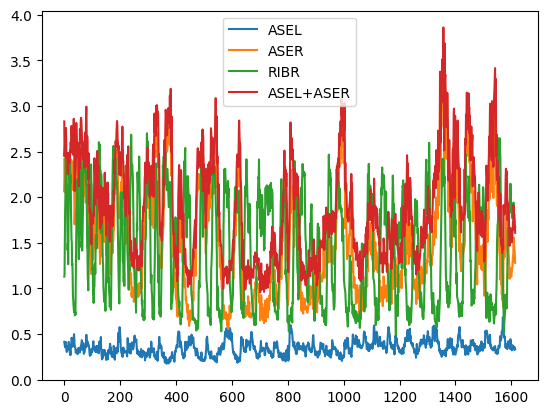

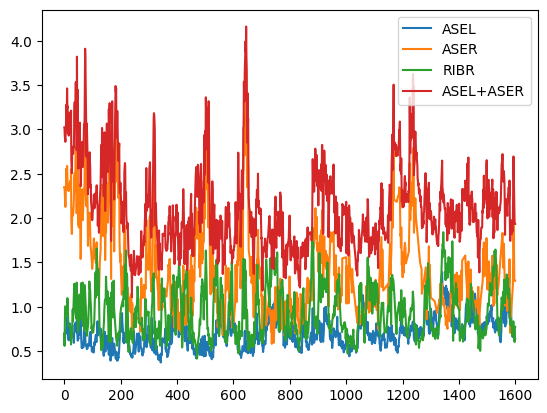

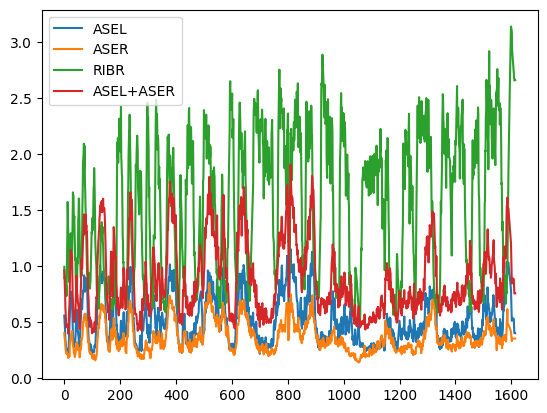

In [5]:
# for each common key, plot the data for all three nodes
for key in common_keys:
    plt.figure()
    plt.plot(asel_data[key], label='ASEL')
    plt.plot(aser_data[key], label='ASER')
    plt.plot(ribr_data[key], label='RIBR')
    plt.plot(asel_data[key]+aser_data[key], label='ASEL+ASER')
    plt.legend()

In [6]:
# find if synchronous ASEL+ASER is more correlated with RIBR than asynchronous ASEL+ASER
# get the correlation between ASEL+ASER and RIBR
for key in common_keys:
    correlation = np.corrcoef(asel_data[key]+aser_data[key], ribr_data[key])[0,1]
    print(correlation)
    # get the correlation between asynchronous ASEL+ASER and RIBR
    correlation = np.corrcoef(asel_data[key], ribr_data[key])[0,1]
    print(correlation)
    correlation = np.corrcoef(aser_data[key], ribr_data[key])[0,1]
    print(correlation)

0.05860605262561411
-0.3732326129757486
0.10826055559373816
0.08370198000751997
0.4630888270502931
-0.07316546598785711
0.07369279909819844
0.032890067626765496
0.12851462069599667


In [7]:
# make thresholded data for each node where threshold is above average val
for key in common_keys:
    asel_thresholded = asel_data[key] > np.mean(asel_data[key])
    aser_thresholded = aser_data[key] > np.mean(aser_data[key])
    ribr_thresholded = ribr_data[key] > np.mean(ribr_data[key])
    # get the correlation between thresholded ASEL+ASER and RIBR
    correlation = np.corrcoef(asel_thresholded*aser_thresholded, ribr_thresholded)[0,1]
    print(correlation)
    # get the correlation between thresholded ASEL and RIBR
    correlation = np.corrcoef(asel_thresholded, ribr_thresholded)[0,1]
    print(correlation)
    # get the correlation between thresholded ASER and RIBR
    correlation = np.corrcoef(aser_thresholded, ribr_thresholded)[0,1]
    print(correlation)


-0.20237353699303676
-0.2941976828559103
0.027370724345913245
0.09144253040480432
0.30672742255436247
-0.06539040962026486
0.03173935304407133
-0.047020938665788325
-0.018078920709959465


In [66]:
import numpy as np

def spike_mask(
    x: np.ndarray,
    win_baseline: int = 40,
    z_thresh: float = 1.3,
    refractory_s: int = 0,
    dtype=bool,
) -> np.ndarray:
    """
    Detect spike events in a 1 Hz calcium trace.

    Parameters
    ----------
    x : np.ndarray
        1-D trace, one sample = one second.
    win_baseline : int
        Window (seconds) for running baseline / noise estimate.
        60 s ≈ one minute works well for stable recordings.
    z_thresh : float
        A sample is a spike if       (x - baseline) / sigma  > z_thresh
    refractory_s : int
        Minimum number of seconds between successive spikes.
    dtype : numpy dtype
        Output mask type (np.uint8, bool, etc.).

    Returns
    -------
    mask : np.ndarray
        Binary mask, shape (len(x),), 1 where a spike is detected.
    """
    x = np.asarray(x, dtype=float)
    N = len(x)
    mask = np.zeros(N, dtype=dtype)

    if N == 0:
        return mask

    # 1.  Running baseline (median filter)  -------------------------------
    #    pad so the first win_baseline samples have a full window
    pad = win_baseline // 2
    padded = np.pad(x, (pad, pad), mode="edge")
    #    rolling median baseline
    baseline = np.empty(N)
    for i in range(N):
        w = padded[i : i + win_baseline]
        baseline[i] = np.median(w)

    # 2.  Robust noise estimate within the same window --------------------
    #    MAD / 0.6745 ≈ σ  (for Gaussian noise)
    sigma = np.empty(N)
    for i in range(N):
        w = padded[i : i + win_baseline]
        sigma[i] = np.median(np.abs(w - np.median(w))) / 0.6745 + 1e-9  # avoid /0

    # 3.  Z-score and threshold ------------------------------------------
    z = (x - baseline) / sigma
    cand = np.where(z > z_thresh)[0]          # candidate indices

    if cand.size == 0:
        return mask

    # 4.  Refractory consolidation ---------------------------------------
    keep = [cand[0]]
    for idx in cand[1:]:
        if idx - keep[-1] >= refractory_s:
            keep.append(idx)

    mask[np.array(keep)] = 1
    return mask



In [67]:
for key in common_keys:
    asel_spikes = spike_mask(asel_data[key])
    aser_spikes = spike_mask(aser_data[key])
    ribr_spikes = spike_mask(ribr_data[key])
    # get the correlation between thresholded ASEL+ASER and RIBR
    correlation = np.corrcoef(asel_spikes & aser_spikes, ribr_spikes)[0,1]
    print("AND:", correlation)
    correlation = np.corrcoef(asel_spikes | aser_spikes, ribr_spikes)[0,1]
    print("OR:", correlation)
    correlation = np.corrcoef(asel_spikes, ribr_spikes)[0,1]
    print("ASEL:", correlation)
    correlation = np.corrcoef(aser_spikes, ribr_spikes)[0,1]
    print("ASER:", correlation)


AND: -0.027085086329863096
OR: -0.070693047156948
ASEL: -0.09719360351672325
ASER: 0.014746174569342697
AND: 0.1252131547332409
OR: 0.14085106522840327
ASEL: 0.17114681308550153
ASER: 0.05398818261822582
AND: -0.02145022426326677
OR: -0.023735621497140053
ASEL: -0.03886773422523207
ASER: -0.0021815552078066525


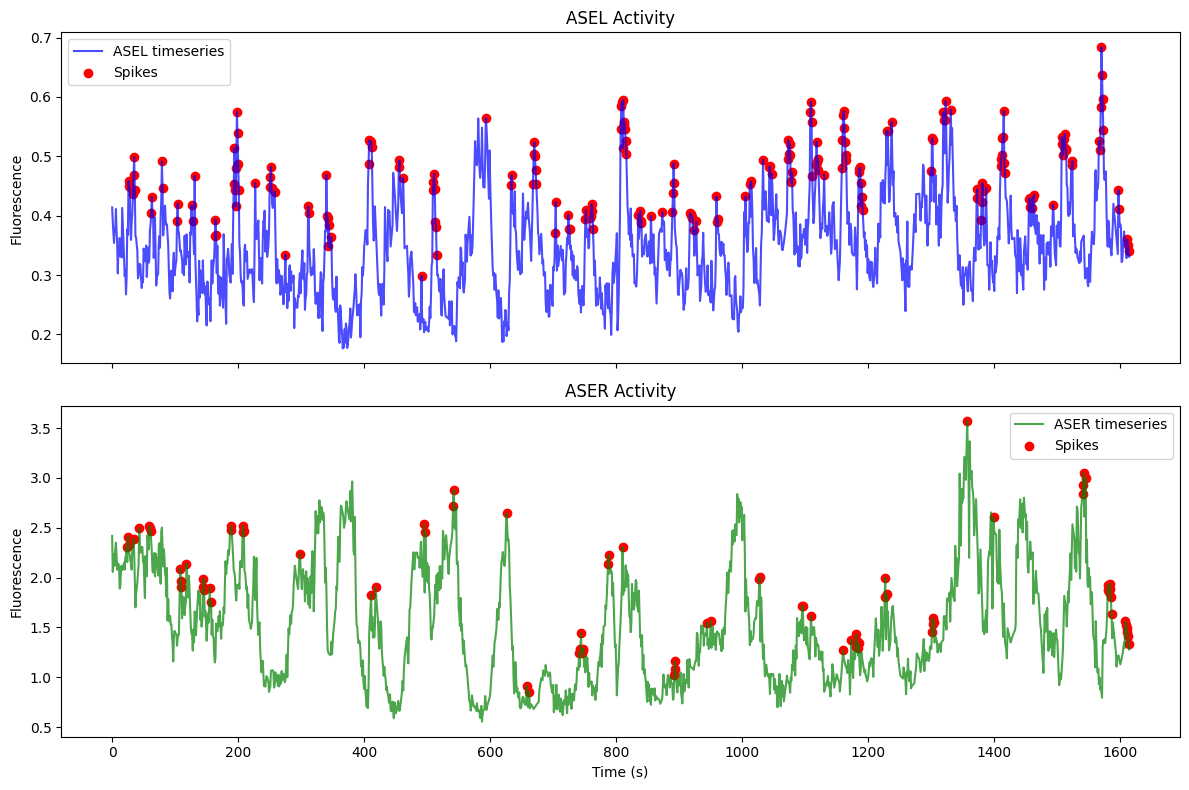

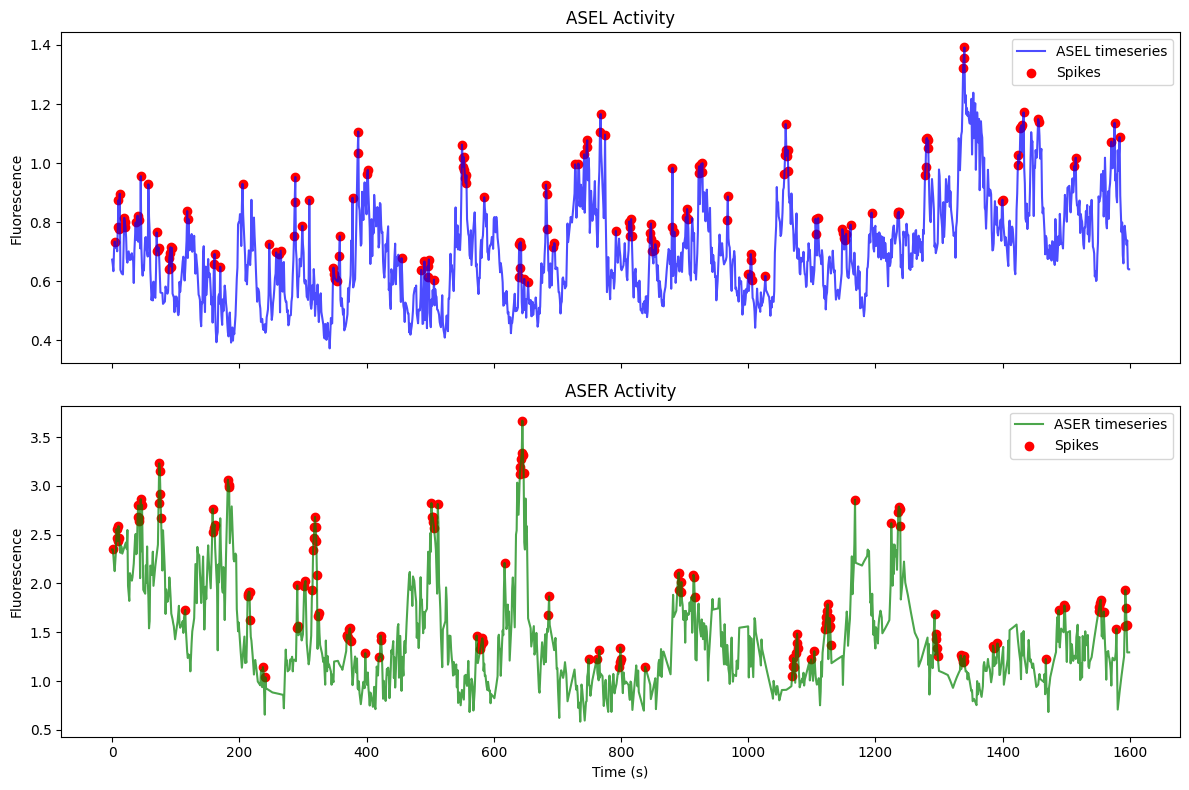

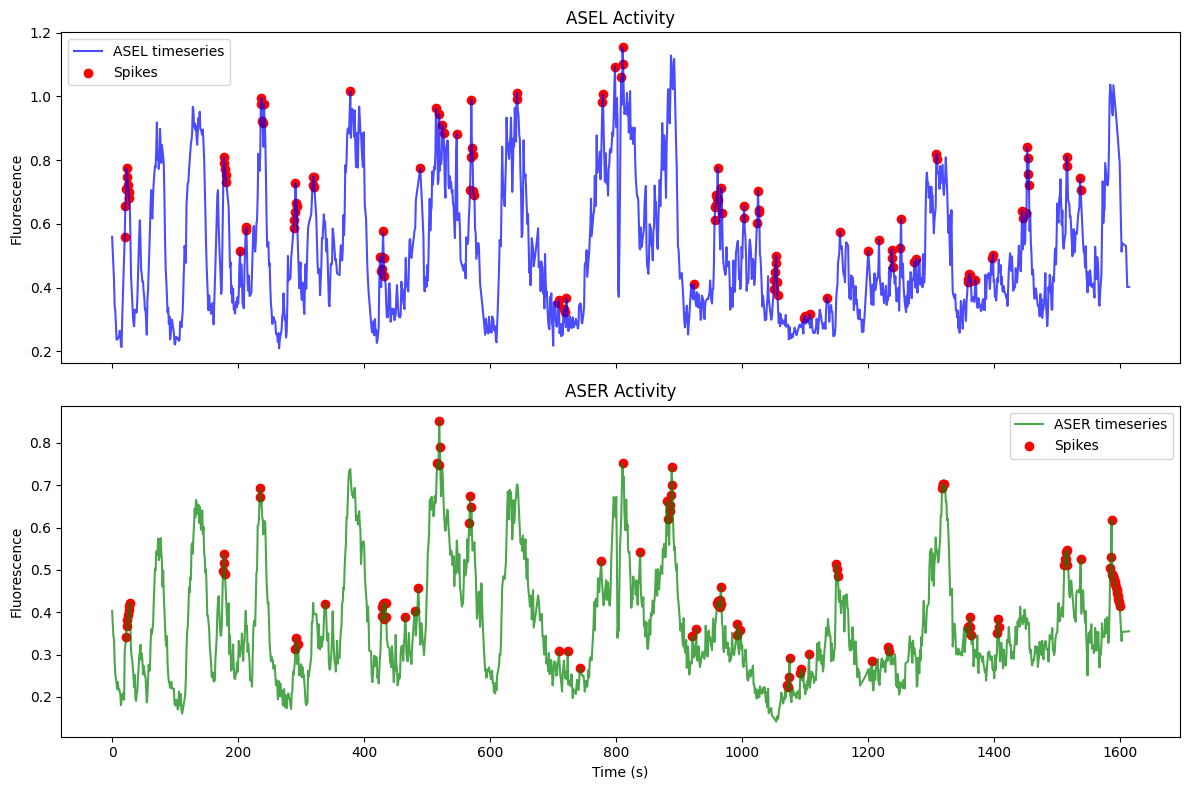

In [68]:
# Plot ASEL and ASER timeseries with spike markers
import matplotlib.pyplot as plt

for key in common_keys:
    # Get spikes and timeseries
    asel_spikes = spike_mask(asel_data[key])
    aser_spikes = spike_mask(aser_data[key])
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    
    # Plot ASEL
    ax1.plot(asel_data[key], 'b-', alpha=0.7, label='ASEL timeseries')
    # Plot spike locations as red dots
    spike_times = np.where(asel_spikes)[0]
    ax1.scatter(spike_times, asel_data[key][spike_times], color='red', 
                marker='o', label='Spikes')
    ax1.set_ylabel('Fluorescence')
    ax1.set_title('ASEL Activity')
    ax1.legend()
    
    # Plot ASER
    ax2.plot(aser_data[key], 'g-', alpha=0.7, label='ASER timeseries')
    # Plot spike locations as red dots
    spike_times = np.where(aser_spikes)[0]
    ax2.scatter(spike_times, aser_data[key][spike_times], color='red',
                marker='o', label='Spikes')
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Fluorescence')
    ax2.set_title('ASER Activity')
    ax2.legend()
    
    plt.tight_layout()
    plt.show()
